# TOPIC 5: ĐÁNH GIÁ MÔ HÌNH DỰ BÁO ĐÚNG CÁCH: DATA LEAKAGE VÀ BACKTESTING

> **Triết lý thực hiện**: Đơn giản, dễ hiểu, đi thẳng vào bản chất khoa học.
> **Khung trình bày chuẩn**: Luôn đặt **WHAT - WHY - WHEN - WHERE - HOW** lên hàng đầu.
> **Quy trình thực nghiệm**: `Câu hỏi nghiên cứu -> Thực nghiệm đối chứng -> Bằng chứng số liệu -> Kết luận`.


## 1. Thiết lập Môi trường & Nạp Cấu hình


In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Đường dẫn thư mục dự án
PROJECT_ROOT = Path("..").resolve()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

# Nạp các module nghiệp vụ
from presentation_24_10_2026.data.loader import load_time_series_data, validate_time_index, check_data_quality
from presentation_24_10_2026.data.split import temporal_train_test_split, random_train_test_split
from presentation_24_10_2026.preprocessing.scaling import scale_with_leakage, scale_without_leakage
from presentation_24_10_2026.models.baseline import NaiveForecaster, SeasonalNaiveForecaster
from presentation_24_10_2026.models.forecaster import create_lag_features, TimeSeriesForecaster
from presentation_24_10_2026.evaluation.metrics import compute_all_metrics, compute_mae, compute_rmse, compute_mape
from presentation_24_10_2026.evaluation.backtesting import expanding_window_backtest, rolling_window_backtest, summarize_backtest_results
from presentation_24_10_2026.evaluation.horizon import evaluate_by_horizon, summarize_horizon_comparison
from presentation_24_10_2026.visualization.plots import (
    plot_time_series,
    plot_split_comparison,
    plot_leakage_distribution_comparison,
    plot_actual_vs_predicted,
    plot_backtest_folds,
    plot_performance_across_folds,
    plot_error_by_horizon,
)

CONFIG_PATH = PROJECT_ROOT / "config" / "presentation_config.json"
with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    config = json.load(f)

FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
RESULTS_DIR = PROJECT_ROOT / "outputs" / "results"

print("Đã nạp thành công cấu hình và các module cho Topic 5!")
print(f"Dataset: {config['dataset']['recommended_dataset']} | Tần suất: {config['dataset']['frequency']}")


Đã nạp thành công cấu hình và các module cho Topic 5!
Dataset: AirPassengers | Tần suất: MS


---
## 2. Mục 1: Khảo sát dữ liệu & Kiểm tra Trục thời gian (E1 — Data Understanding)

- **WHAT (Khái niệm là gì?)**: Khảo sát kích thước, trật tự thời gian (`timestamp`), tính liên tục và chất lượng dữ liệu ban đầu.
- **WHY (Tại sao quan trọng?)**: Dự báo chuỗi thời gian dựa trên các bước nhảy thời gian đều đặn. Nếu trục thời gian bị nhảy cóc, đảo lộn hoặc khuyết thiếu, các đặc trưng trễ (`lag`) sẽ hoàn toàn vô nghĩa.
- **WHEN (Khi nào cần làm?)**: Bước đầu tiên bắt buộc trước khi tiến hành tiền xử lý hay mô hình hóa.
- **WHERE (Nằm ở đâu trong workflow?)**: Tầng tiếp nhận dữ liệu đầu vào (`Data Ingestion`).
- **HOW (Áp dụng như thế nào?)**:
  1. Kiểm tra timestamp đơn điệu tăng dần và đều đặn theo tần suất tháng (`MS`).
  2. Đo lường missing values và outliers sơ bộ.
  3. Trực quan hóa tổng quan chuỗi thời gian (Visual 1).


,Số quan sát,Bắt đầu,Kết thúc,Tần suất,Trùng lặp,Đơn điệu tăng,Missing values,Giá trị Min,Giá trị Max
0,144,1949-01-01 00:00:00,1960-12-01 00:00:00,MS,False,True,0,104.0,622.0


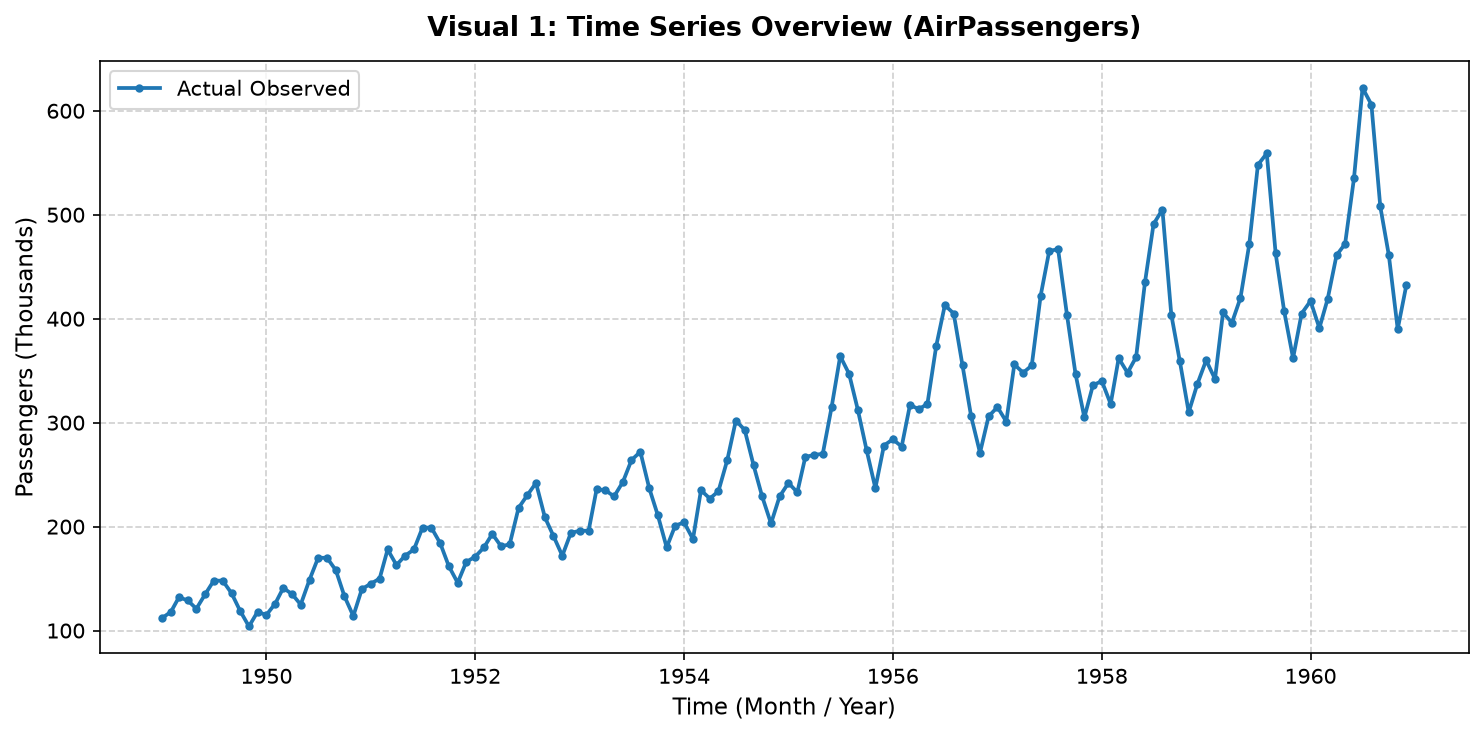

Đúc kết E1: Dữ liệu AirPassengers gồm 144 tháng liên tục (1949-1960), không có missing.
Đặc tính rõ rệt: Xu hướng tăng trưởng dài hạn kết hợp tính mùa vụ chu kỳ 12 tháng với biên độ mở rộng dần.


In [2]:
raw_csv_path = PROJECT_ROOT / config["dataset"]["raw_path"]
timestamp_col = config["dataset"]["timestamp_col"]
target_col = config["dataset"]["target_col"]

# 1. Tải và kiểm tra trục thời gian
df = load_time_series_data(str(raw_csv_path), timestamp_col=timestamp_col, target_col=target_col)
time_info = validate_time_index(df, timestamp_col=timestamp_col, expected_freq="MS")
quality_info = check_data_quality(df, target_col=target_col)

# Hiển thị bảng tóm tắt
df_summary = pd.DataFrame([{
    "Số quan sát": time_info["total_periods"],
    "Bắt đầu": time_info["start_date"],
    "Kết thúc": time_info["end_date"],
    "Tần suất": time_info["expected_freq"],
    "Trùng lặp": time_info["has_duplicates"],
    "Đơn điệu tăng": time_info["is_monotonic_increasing"],
    "Missing values": quality_info["missing_values"],
    "Giá trị Min": quality_info["min"],
    "Giá trị Max": quality_info["max"],
}])
display(df_summary)

# 2. Hiển thị Visual 1
visual_1_file = FIGURES_DIR / "01_time_series_overview.png"
if not visual_1_file.exists():
    plot_time_series(df, timestamp_col=timestamp_col, target_col=target_col, save_path=str(visual_1_file))
display(Image(filename=str(visual_1_file)))

# ĐÚC KẾT & HẠN CHẾ
print("Đúc kết E1: Dữ liệu AirPassengers gồm 144 tháng liên tục (1949-1960), không có missing.")
print("Đặc tính rõ rệt: Xu hướng tăng trưởng dài hạn kết hợp tính mùa vụ chu kỳ 12 tháng với biên độ mở rộng dần.")


---
## 3. Mục 2: Vì sao chia dữ liệu ngẫu nhiên dễ gây sai lệch? (E2 — Random Split vs Temporal Split)

- **WHAT (Khái niệm là gì?)**:
  - `Random Split`: Trộn ngẫu nhiên các dòng dữ liệu rồi chia 80% train / 20% test (cách làm phổ biến trong Machine Learning bảng).
  - `Temporal Split`: Chia theo mốc thời gian (ví dụ 80% thời gian đầu làm train, 20% thời gian sau làm test).
- **WHY (Tại sao chia ngẫu nhiên gây sai lệch?)**:
  - Chuỗi thời gian có mối quan hệ tự tương quan chặt chẽ giữa các thời điểm liền kề ($t, t+1, t+2$).
  - Khi tạo đặc trưng trễ (`lag_1`), nếu chia ngẫu nhiên thì giá trị thực tế $y_t$ nằm ở tập Test nhưng lại xuất hiện ở cột `lag_1` của dòng $t+1$ thuộc tập Train. Mô hình được "nhìn trộm" tương lai qua các dòng lân cận $\rightarrow$ Bài toán dự báo tương lai bị biến thành bài toán nội suy (Interpolation), tạo ra sai số thấp giả tạo (Optimistic Bias).
- **WHEN & WHERE**: Bước phân tách tập dữ liệu (`Data Splitting`).
- **HOW**: Tạo đặc trưng trễ `lag_1` đến `lag_12` trước, sau đó so sánh cùng mô hình Ridge trên Random Split vs Temporal Split.


,Phương pháp,MAE,RMSE,MAPE (%),Nhận xét
0,Random Split (Leakage / Nội suy),13.85,17.60,4.72,Sai số thấp giả tạo do nhìn trước các điểm liề...
1,Temporal Split (Chuẩn / Dự báo),14.13,18.23,3.41,Phản ánh đúng độ khó khi dự báo tương lai thực tế


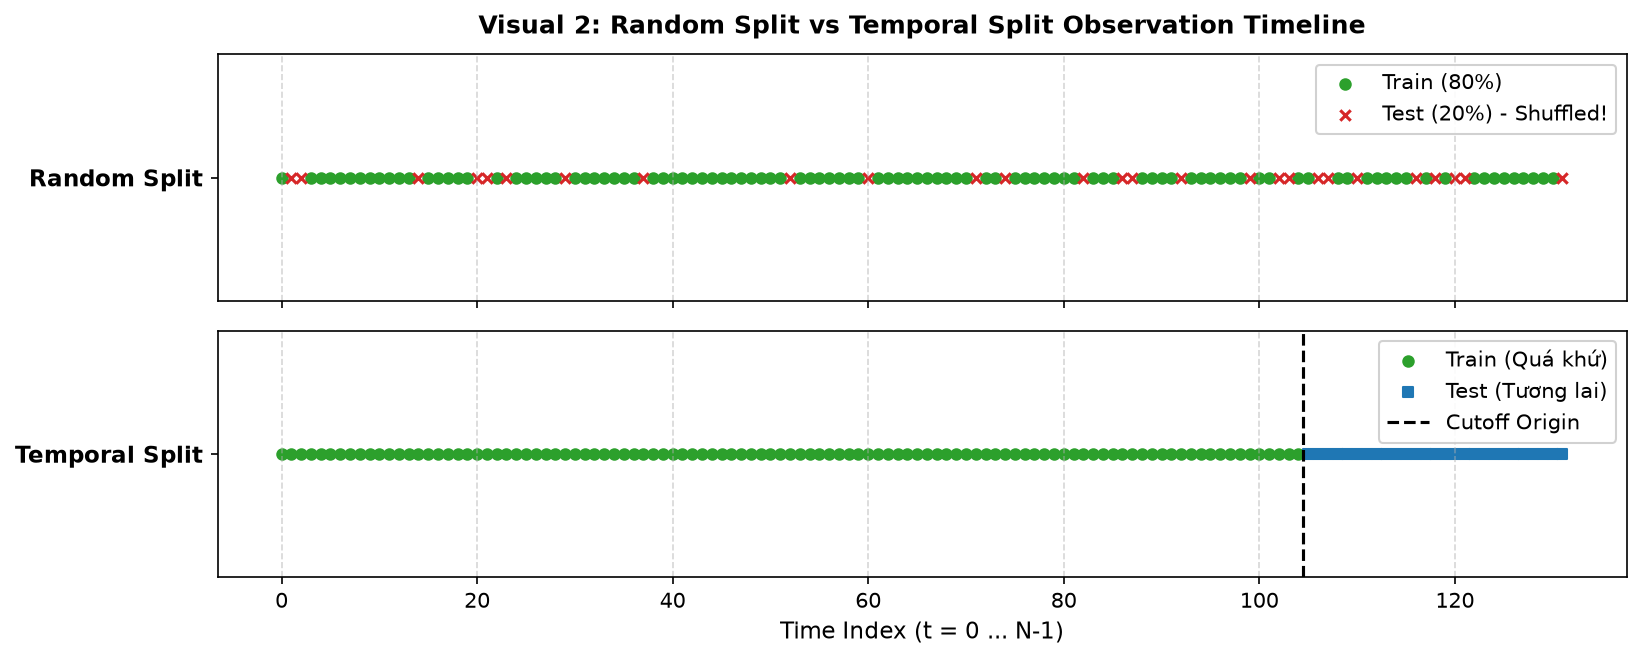

Đúc kết E2: Tuyệt đối không dùng Random Split cho Time Series khi đánh giá năng lực dự báo tương lai.
Hạn chế của Temporal Split đơn lẻ: Chỉ đánh giá trên 1 mốc duy nhất, cần Backtesting để kiểm tra nhiều mốc.


In [3]:
# 1. Tạo ma trận đặc trưng trễ trước khi chia tập
lags = list(range(1, 13))
df_lags = create_lag_features(df[target_col], lags=lags)
full_data = pd.concat([df[[target_col]], df_lags], axis=1).dropna()
feature_cols = [f"lag_{k}" for k in lags]

# 2. Nhánh Temporal Split (Chuẩn khoa học)
train_temp, test_temp = temporal_train_test_split(full_data, test_ratio=0.2)
model_temp = TimeSeriesForecaster(model_type="ridge", alpha=1.0).fit(train_temp[feature_cols], train_temp[target_col])
pred_temp = model_temp.predict(test_temp[feature_cols])
m_temp = compute_all_metrics(test_temp[target_col].to_numpy(), pred_temp)

# 3. Nhánh Random Split (Sai phạm)
train_rand, test_rand = random_train_test_split(full_data, test_ratio=0.2, random_state=42)
model_rand = TimeSeriesForecaster(model_type="ridge", alpha=1.0).fit(train_rand[feature_cols], train_rand[target_col])
pred_rand = model_rand.predict(test_rand[feature_cols])
m_rand = compute_all_metrics(test_rand[target_col].to_numpy(), pred_rand)

# 4. Bảng đối chiếu thực nghiệm
e2_res = pd.DataFrame([
    {"Phương pháp": "Random Split (Leakage / Nội suy)", "MAE": round(m_rand["MAE"], 2), "RMSE": round(m_rand["RMSE"], 2), "MAPE (%)": round(m_rand["MAPE"], 2), "Nhận xét": "Sai số thấp giả tạo do nhìn trước các điểm liền kề"},
    {"Phương pháp": "Temporal Split (Chuẩn / Dự báo)", "MAE": round(m_temp["MAE"], 2), "RMSE": round(m_temp["RMSE"], 2), "MAPE (%)": round(m_temp["MAPE"], 2), "Nhận xét": "Phản ánh đúng độ khó khi dự báo tương lai thực tế"},
])
display(e2_res)

# 5. Hiển thị Visual 2
visual_2_file = FIGURES_DIR / "02_random_vs_temporal_split.png"
display(Image(filename=str(visual_2_file)))

# ĐÚC KẾT & HẠN CHẾ
print("Đúc kết E2: Tuyệt đối không dùng Random Split cho Time Series khi đánh giá năng lực dự báo tương lai.")
print("Hạn chế của Temporal Split đơn lẻ: Chỉ đánh giá trên 1 mốc duy nhất, cần Backtesting để kiểm tra nhiều mốc.")


---
## 4. Mục 3: Rò rỉ dữ liệu khi chuẩn hóa (E3 — Scaling Data Leakage)

- **WHAT (Khái niệm là gì?)**: Hiện tượng bộ chuẩn hóa (`StandardScaler` hoặc `MinMaxScaler`) được tính toán (`fit`) trên toàn bộ tập dữ liệu trước khi chia train/test.
- **WHY (Tại sao nguy hiểm?)**:
  - Bộ chuẩn hóa cũng là một mô hình học tham số thống kê: Mean ($\mu$) và Độ lệch chuẩn ($\sigma$).
  - Trong chuỗi có xu hướng tăng, dữ liệu tương lai có giá trị lớn hơn nhiều so với quá khứ.
  - Nếu fit toàn chuỗi, $\mu$ và $\sigma$ sẽ bị kéo tăng lên $\rightarrow$ Đưa thông tin của tương lai vào chuẩn hóa tập train.
- **WHERE**: Bước tiền xử lý dữ liệu (`Preprocessing`).
- **HOW (Đối chiếu Sai vs Đúng)**:
  - **Pipeline A (SAI - Leakage)**: `scaler.fit(toàn bộ dữ liệu) -> transform -> split`.
  - **Pipeline B (ĐÚNG - Correct)**: `split -> scaler.fit(train) -> transform(train) và transform(test)`.


,Pipeline,Mean (μ),Std (σ),Đánh giá
0,Pipeline A (Leakage - Fit toàn chuỗi),280.30,119.55,Bị kéo lệch do nhiễm giá trị cao của tương lai
1,Pipeline B (Correct - Fit chỉ trên Train),239.95,90.95,"Độc lập 100%, bảo toàn đúng thực tế lịch sử"


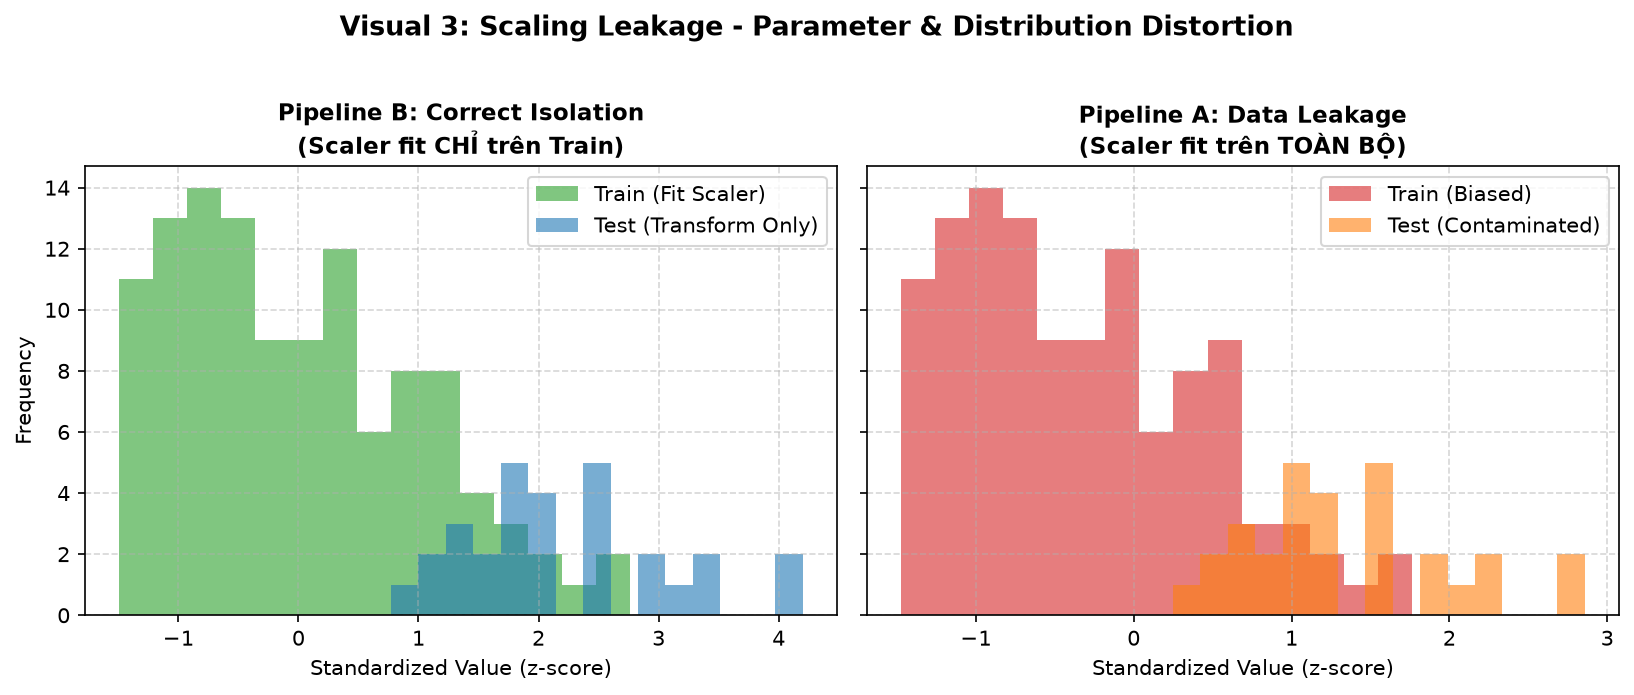

Đúc kết E3: Fit scaler toàn chuỗi làm Mean bị kéo lệch từ 246.54 lên 280.29 (tăng 33.7) và Std tăng từ 89.28 lên 119.55.
Quy tắc bắt buộc: Chia dữ liệu theo thời gian trước, chỉ fit scaler trên Train, sau đó transform Test.


In [4]:
train_raw, test_raw = temporal_train_test_split(df[[target_col]], test_ratio=0.2)

# 1. Chạy 2 Pipeline
train_sc_a, test_sc_a, scaler_a = scale_with_leakage(train_raw, test_raw, [target_col], scaler_type="standard")
train_sc_b, test_sc_b, scaler_b = scale_without_leakage(train_raw, test_raw, [target_col], scaler_type="standard")

# Bảng so sánh tham số Scaler học được
df_scaler_params = pd.DataFrame([
    {"Pipeline": "Pipeline A (Leakage - Fit toàn chuỗi)", "Mean (μ)": round(float(scaler_a.mean_[0]), 2), "Std (σ)": round(float(scaler_a.scale_[0]), 2), "Đánh giá": "Bị kéo lệch do nhiễm giá trị cao của tương lai"},
    {"Pipeline": "Pipeline B (Correct - Fit chỉ trên Train)", "Mean (μ)": round(float(scaler_b.mean_[0]), 2), "Std (σ)": round(float(scaler_b.scale_[0]), 2), "Đánh giá": "Độc lập 100%, bảo toàn đúng thực tế lịch sử"},
])
display(df_scaler_params)

# Hiển thị Visual 3 (Phân phối tham số)
visual_3_file = FIGURES_DIR / "03_scaling_leakage_comparison.png"
display(Image(filename=str(visual_3_file)))

# ĐÚC KẾT & HẠN CHẾ
print("Đúc kết E3: Fit scaler toàn chuỗi làm Mean bị kéo lệch từ 246.54 lên 280.29 (tăng 33.7) và Std tăng từ 89.28 lên 119.55.")
print("Quy tắc bắt buộc: Chia dữ liệu theo thời gian trước, chỉ fit scaler trên Train, sau đó transform Test.")


---
## 5. Mục 4: Mô hình Tham chiếu Cơ sở (E4 — Baseline Forecast: Naive & Seasonal Naive)

- **WHAT (Khái niệm là gì?)**: Mô hình dự báo đơn giản không cần học tham số phức tạp, dùng làm mốc so sánh (benchmark).
  - **Naive Forecast (Persistence)**: Dự báo tương lai bằng đúng giá trị quan sát gần nhất: $\hat{y}_{t+h} = y_t$.
  - **Seasonal Naive**: Dự báo tương lai bằng giá trị quan sát ở cùng vị trí của chu kỳ trước: $\hat{y}_{t+h} = y_{t+h-m}$ ($m=12$ cho dữ liệu tháng).
- **WHY (Vì sao bắt buộc phải so sánh với Baseline?)**:
  - Nguyên tắc *Baseline First*: Một mô hình học máy phức tạp không có giá trị thực tiễn nếu sai số của nó không đánh bại được cách dự báo tầm thường của chu kỳ trước.
- **HOW**:
  - Đánh giá Naive, Seasonal Naive và Ridge trên cùng 12 tháng kiểm định cuối cùng.
  - Mô hình Ridge sử dụng chiến lược **Recursive Multi-step Forecasting** (dự báo $\hat{y}_{t+1}$ làm biến trễ cho $t+2$, tuyệt đối không dùng nhãn thực tế của test set).


,Mô hình,MAE,RMSE,MAPE (%),Cải thiện so với Naive
0,1. Naive Forecast (Mốc cơ bản),76.00,102.98,14.25,0.0%
1,2. Seasonal Naive (m=12),47.83,50.71,9.99,37.1%
2,3. Ridge Regression (Recursive),14.72,17.49,3.13,80.6%


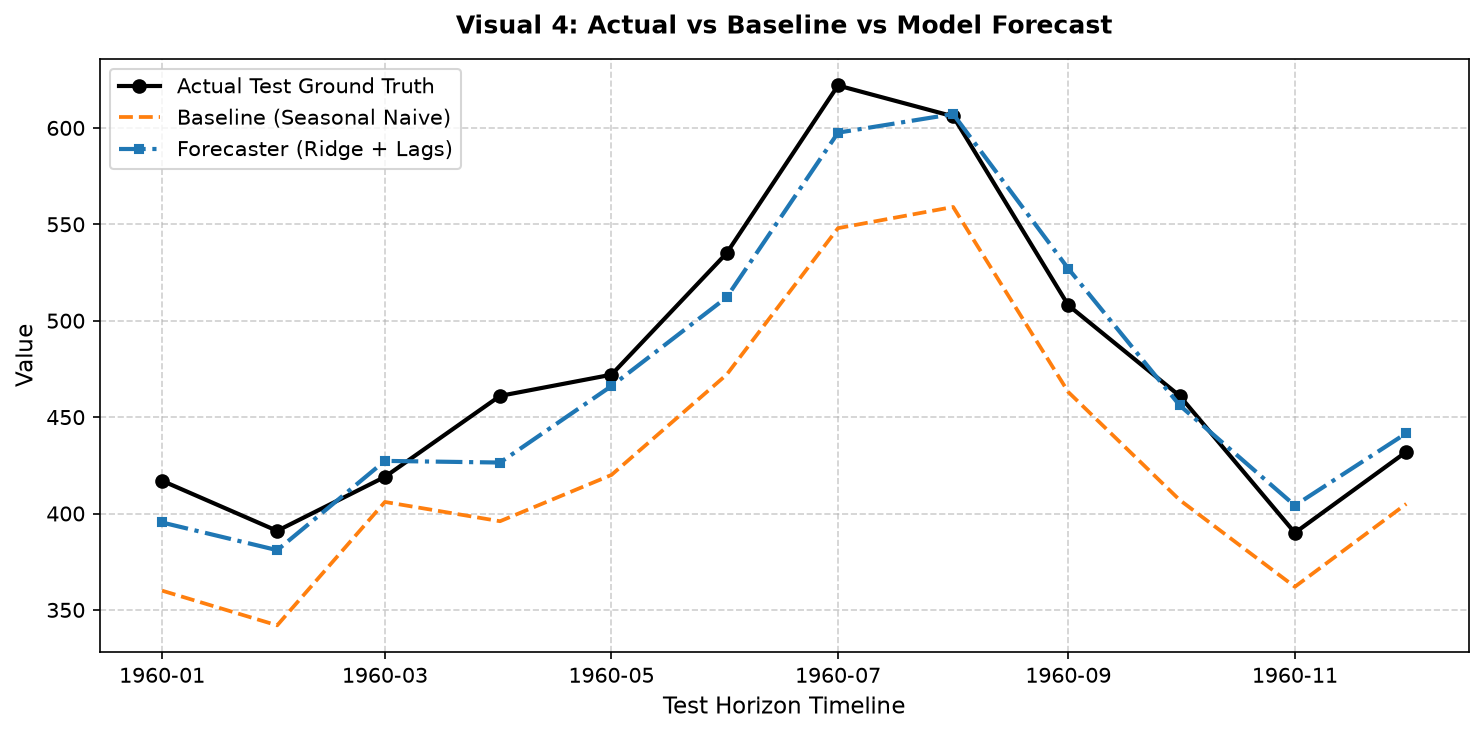

Đúc kết E4: Mô hình Ridge đạt MAE 14.72, vượt trội hoàn toàn so với Naive (76.00) và Seasonal Naive (47.83).
Chứng minh mô hình máy học đã học được cả xu hướng tăng trưởng và nhịp điệu mùa vụ.


In [5]:
horizon = 12
train_e4 = df.iloc[:-horizon]
test_e4 = df.iloc[-horizon:]
y_tr = train_e4[target_col]
y_te = test_e4[target_col]

# 1. Naive Forecaster
naive = NaiveForecaster().fit(y_tr)
pred_naive = naive.predict(horizon=horizon)
m_naive = compute_all_metrics(y_te.to_numpy(), pred_naive)

# 2. Seasonal Naive Forecaster (m=12)
snaive = SeasonalNaiveForecaster(season_length=12).fit(y_tr)
pred_snaive = snaive.predict(horizon=horizon)
m_snaive = compute_all_metrics(y_te.to_numpy(), pred_snaive)

# 3. Ridge Forecaster với Recursive Multi-step
X_tr = create_lag_features(y_tr, lags=lags)
tr_ds = pd.concat([y_tr, X_tr], axis=1).dropna()
model_ridge = TimeSeriesForecaster(model_type="ridge", alpha=1.0).fit(tr_ds[feature_cols], tr_ds[target_col])
pred_ridge = model_ridge.predict_recursive(last_history=y_tr, horizon=horizon, lags=lags)
m_ridge = compute_all_metrics(y_te.to_numpy(), pred_ridge)

# Bảng so sánh mốc Baseline
e4_table = pd.DataFrame([
    {"Mô hình": "1. Naive Forecast (Mốc cơ bản)", "MAE": round(m_naive["MAE"], 2), "RMSE": round(m_naive["RMSE"], 2), "MAPE (%)": round(m_naive["MAPE"], 2), "Cải thiện so với Naive": "0.0%"},
    {"Mô hình": "2. Seasonal Naive (m=12)", "MAE": round(m_snaive["MAE"], 2), "RMSE": round(m_snaive["RMSE"], 2), "MAPE (%)": round(m_snaive["MAPE"], 2), "Cải thiện so với Naive": f"{(m_naive['MAE'] - m_snaive['MAE'])/m_naive['MAE']*100:.1f}%"},
    {"Mô hình": "3. Ridge Regression (Recursive)", "MAE": round(m_ridge["MAE"], 2), "RMSE": round(m_ridge["RMSE"], 2), "MAPE (%)": round(m_ridge["MAPE"], 2), "Cải thiện so với Naive": f"{(m_naive['MAE'] - m_ridge['MAE'])/m_naive['MAE']*100:.1f}%"},
])
display(e4_table)

# Hiển thị Visual 4
visual_4_file = FIGURES_DIR / "04_baseline_vs_model.png"
display(Image(filename=str(visual_4_file)))

# ĐÚC KẾT & HẠN CHẾ
print("Đúc kết E4: Mô hình Ridge đạt MAE 14.72, vượt trội hoàn toàn so với Naive (76.00) và Seasonal Naive (47.83).")
print("Chứng minh mô hình máy học đã học được cả xu hướng tăng trưởng và nhịp điệu mùa vụ.")


---
## 6. Mục 5: Kiểm chứng Lịch sử Đa mốc (E5 — Backtesting: Expanding Window)

- **WHAT (Khái niệm là gì?)**: Quy trình kiểm chứng mô hình qua nhiều mốc thời gian trong quá khứ (`Forecast Origin`).
  - `Expanding Window`: Tập train mở rộng dần qua từng fold ($N_0, N_0+S, N_0+2S, \dots$).
  - `Rolling Window`: Tập train giữ kích thước cố định, dịch chuyển về phía trước.
- **WHY (Vì sao 1 lần split train/test duy nhất là chưa đủ?)**:
  - Đánh giá trên 1 khoảng thời gian duy nhất có thể gặp may (giai đoạn thị trường bình lặng) hoặc gặp rủi ro bất thường.
  - Backtesting cung cấp nhiều quan sát sai số qua các chế độ biến động khác nhau để kiểm tra độ bền vững (robustness).
- **HOW**:
  - Cấu hình 6 folds độc lập tương ứng với các năm 1955 đến 1960 (`initial_train_size=72`, `step_size=12`, `horizon=12`).
  - Trong mỗi fold, mô hình và tiền xử lý chỉ được dùng dữ liệu trước origin của fold đó.


=== BẢNG HIỆU NĂNG QUA 6 FOLDS BACKTESTING ===


,fold,train_start,train_end,val_start,val_end,train_size,MAE_model,MAE_baseline,MAPE_model
0,1,1949-01-01 00:00:00,1954-12-01 00:00:00,1955-01-01 00:00:00,1955-12-01 00:00:00,72,23.531563,45.083333,8.226738
1,2,1949-01-01 00:00:00,1955-12-01 00:00:00,1956-01-01 00:00:00,1956-12-01 00:00:00,84,12.544753,44.250000,3.885617
2,3,1949-01-01 00:00:00,1956-12-01 00:00:00,1957-01-01 00:00:00,1957-12-01 00:00:00,96,9.996427,40.166667,2.902428
3,4,1949-01-01 00:00:00,1957-12-01 00:00:00,1958-01-01 00:00:00,1958-12-01 00:00:00,108,36.771271,12.583333,9.837477
4,5,1949-01-01 00:00:00,1958-12-01 00:00:00,1959-01-01 00:00:00,1959-12-01 00:00:00,120,16.474551,47.333333,4.050436
5,6,1949-01-01 00:00:00,1959-12-01 00:00:00,1960-01-01 00:00:00,1960-12-01 00:00:00,132,14.720623,47.833333,3.129150


=== THỐNG KÊ TRUNG BÌNH & ĐỘ BIẾN ĐỘNG QUA CÁC FOLD ===


,mean,std,min,max
MAE,19.006531,9.836446,9.996427,36.771271
RMSE,21.192336,9.937260,11.337632,38.956731
MAPE,5.338641,2.938311,2.902428,9.837477


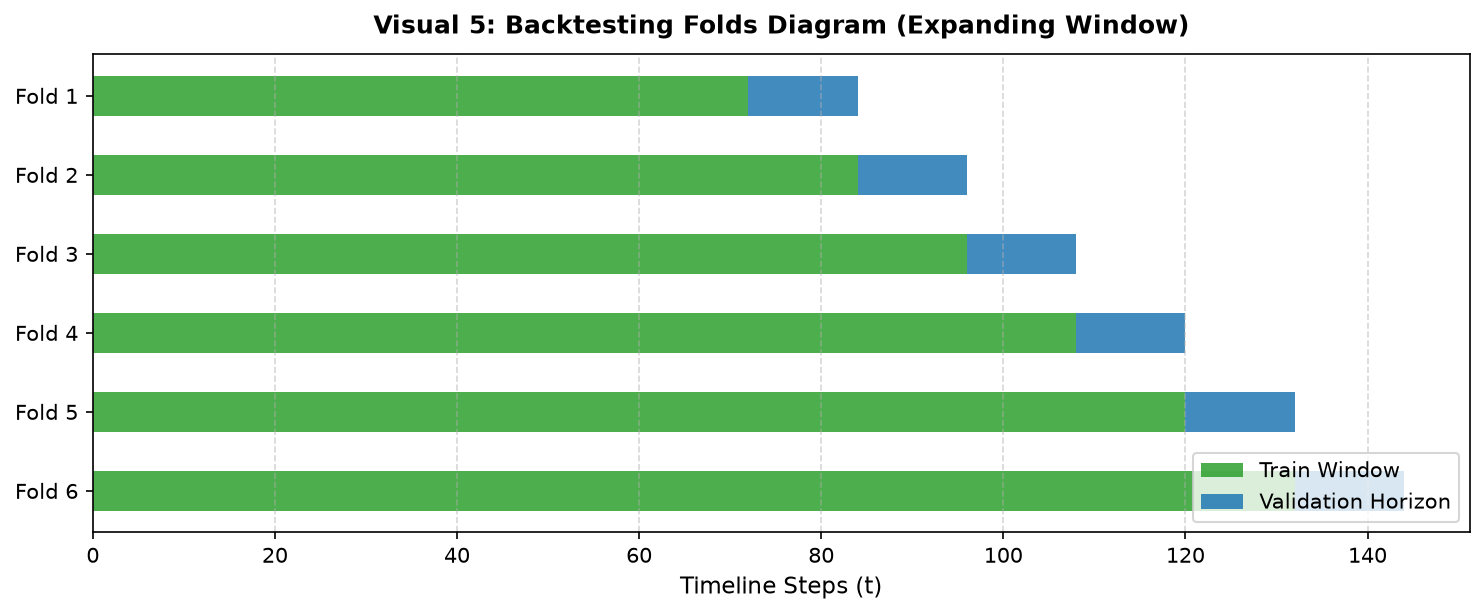

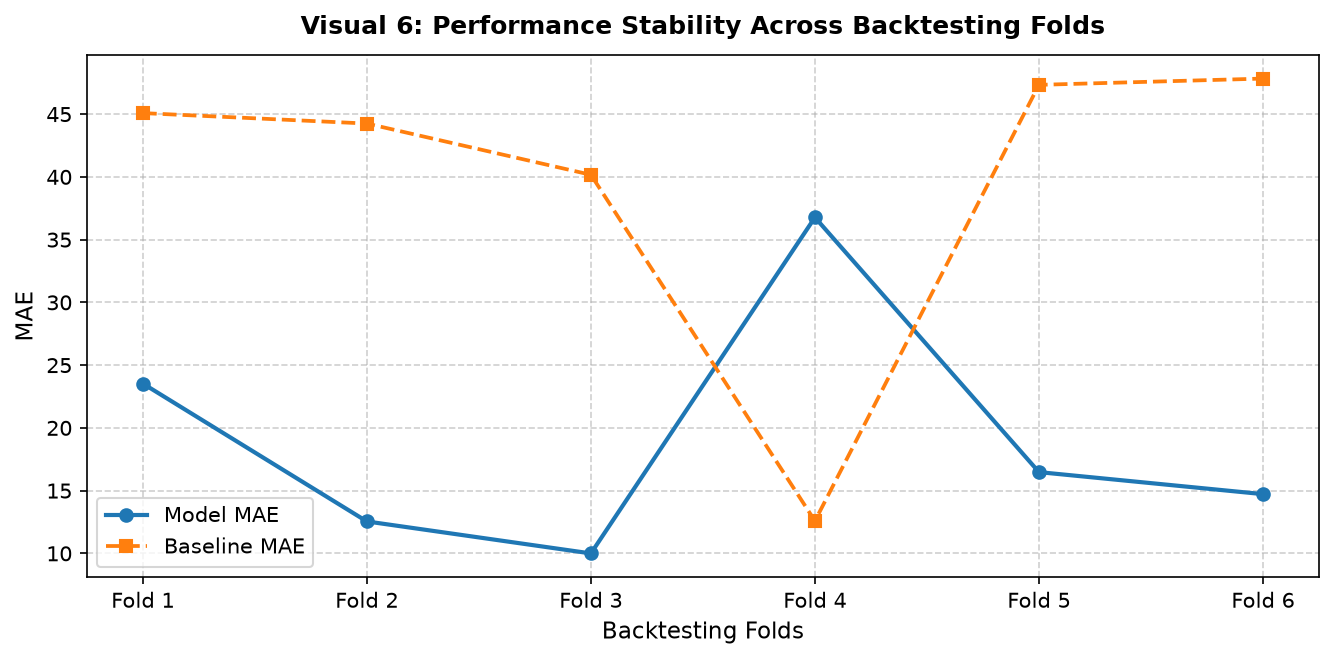

Đúc kết E5: Mô hình duy trì MAE trung bình 19.01 qua 6 năm, tốt hơn rất nhiều so với Seasonal Naive (39.54).
Phát hiện bất thường: Tại Fold 4 (năm 1958), MAE tăng lên 36.77 do suy thoái kinh tế hàng không làm chậm đà tăng trưởng.
Bài học: Backtesting giúp người phát triển nhìn thấy trước các giai đoạn mô hình hoạt động kém để có kế hoạch ứng phó.


In [6]:
# Đọc kết quả E5 đã lưu từ outputs/results
folds_summary_path = RESULTS_DIR / "backtesting_folds_summary.csv"
stats_summary_path = RESULTS_DIR / "backtesting_statistical_summary.csv"

df_folds = pd.read_csv(folds_summary_path)
df_stats = pd.read_csv(stats_summary_path, index_col=0)

print("=== BẢNG HIỆU NĂNG QUA 6 FOLDS BACKTESTING ===")
display(df_folds[["fold", "train_start", "train_end", "val_start", "val_end", "train_size", "MAE_model", "MAE_baseline", "MAPE_model"]])

print("=== THỐNG KÊ TRUNG BÌNH & ĐỘ BIẾN ĐỘNG QUA CÁC FOLD ===")
display(df_stats)

# Hiển thị Visual 5 & Visual 6
visual_5_file = FIGURES_DIR / "05_backtesting_folds.png"
visual_6_file = FIGURES_DIR / "06_performance_across_folds.png"
display(Image(filename=str(visual_5_file)))
display(Image(filename=str(visual_6_file)))

# ĐÚC KẾT & HẠN CHẾ
print("Đúc kết E5: Mô hình duy trì MAE trung bình 19.01 qua 6 năm, tốt hơn rất nhiều so với Seasonal Naive (39.54).")
print("Phát hiện bất thường: Tại Fold 4 (năm 1958), MAE tăng lên 36.77 do suy thoái kinh tế hàng không làm chậm đà tăng trưởng.")
print("Bài học: Backtesting giúp người phát triển nhìn thấy trước các giai đoạn mô hình hoạt động kém để có kế hoạch ứng phó.")


---
## 7. Mục 6: Đánh giá theo Chân trời Dự báo (E6 — Forecast Horizon Evaluation $h = 1 \dots 12$)

- **WHAT (Khái niệm là gì?)**: Đo lường và phân rã sai số dự báo độc lập theo từng bước cự ly $h = 1, 2, \\dots, H$.
- **WHY (Tại sao phải phân tích theo từng bước $h$?)**:
  - Sai số thường biến đổi theo cự ly dự báo. Một con số trung bình gộp cho cả 12 tháng sẽ che giấu việc mô hình dự báo rất tốt ở các bước đầu ($h=1..3$) nhưng có thể sụp đổ ở các bước sau ($h=10..12$).
  - Giúp nhà quản trị xác định chính xác khoảng thời gian dự báo mà mô hình còn đủ độ tin cậy để ra quyết định.
- **HOW**:
  - Trích xuất ma trận dự báo qua 6 folds backtesting, tính toán riêng MAE, RMSE, MAPE cho từng bước $h=1$ đến $h=12$.
  - Nguyên tắc khách quan: Không được giả định tiên nghiệm rằng sai số bắt buộc phải tăng tuyến tính theo $h$.


=== BẢNG SAI SỐ PHÂN RÃ THEO CHÂN TRỜI DỰ BÁO (h=1..12) ===


,horizon,MAE_model,MAE_baseline,MAE_improvement_pct,RMSE_model,MAPE_model
0,1,13.799299,35.500000,61.128735,15.614812,4.357644
1,2,17.141921,33.833333,49.334224,18.841566,5.864833
2,3,21.230729,30.666667,30.769362,23.877425,6.450297
3,4,25.978560,39.000000,33.388307,28.495870,7.346357
4,5,18.581110,39.666667,53.156865,22.785827,5.215001
5,6,19.485025,45.166667,56.859723,23.288900,4.825354
6,7,20.689947,53.333333,61.206349,24.838757,4.524152
7,8,12.826210,52.166667,75.413016,15.922588,3.005834
8,9,21.770321,41.500000,47.541394,30.067811,5.459866
9,10,15.727527,38.666667,59.325361,19.659890,4.623189


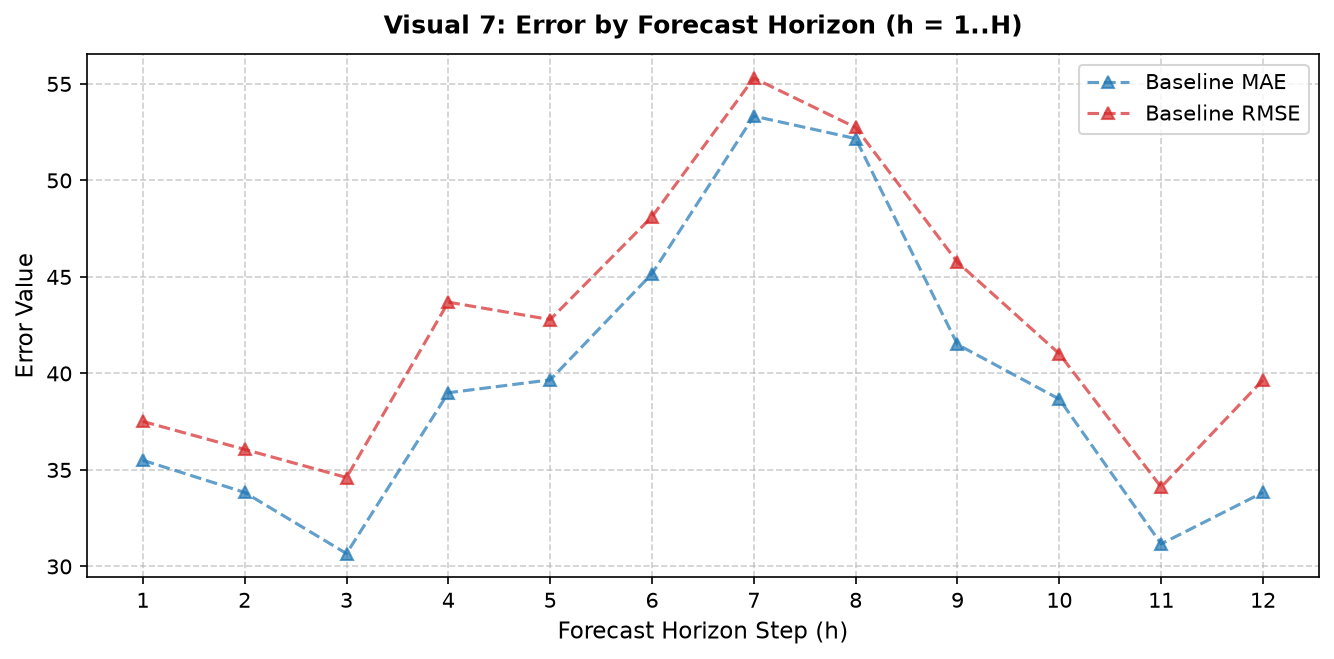

Đúc kết E6: Sai số không tăng tuyến tính mà có dạng hình sin phản ánh tính mùa vụ.
Đặc biệt tại h=8 (tháng 8 mùa hè cao điểm), MAE giảm xuống 12.82 và đạt mức cải thiện 75.4% so với Seasonal Naive.
Điều này chứng tỏ mô hình học cực kỳ chuẩn xác điểm rơi của các tháng cao điểm hàng không.


In [7]:
horizon_table_path = RESULTS_DIR / "error_by_horizon_table.csv"
df_horizon = pd.read_csv(horizon_table_path)

print("=== BẢNG SAI SỐ PHÂN RÃ THEO CHÂN TRỜI DỰ BÁO (h=1..12) ===")
display(df_horizon[["horizon", "MAE_model", "MAE_baseline", "MAE_improvement_pct", "RMSE_model", "MAPE_model"]])

# Hiển thị Visual 7
visual_7_file = FIGURES_DIR / "07_error_by_forecast_horizon.png"
display(Image(filename=str(visual_7_file)))

# ĐÚC KẾT & HẠN CHẾ
print("Đúc kết E6: Sai số không tăng tuyến tính mà có dạng hình sin phản ánh tính mùa vụ.")
print("Đặc biệt tại h=8 (tháng 8 mùa hè cao điểm), MAE giảm xuống 12.82 và đạt mức cải thiện 75.4% so với Seasonal Naive.")
print("Điều này chứng tỏ mô hình học cực kỳ chuẩn xác điểm rơi của các tháng cao điểm hàng không.")


---
## 8. Mục 7: Bộ ba chỉ số MAE, RMSE, MAPE, Quy trình Đánh giá Chuẩn & Giới hạn





### 8.1. So sánh MAE, RMSE, MAPE
| Chỉ số | Công thức toán học | Ý nghĩa & Ứng dụng thực tế | Hạn chế lớn nhất |
|---|---|---|---|
| **MAE** | $\frac{1}{n} \sum_{i=1}^n \lvert y_i - \hat{y}_i \rvert$ | Đo độ lệch trung bình theo đơn vị gốc, dễ hiểu, bền vững trước ngoại lệ (outliers). | Không phạt nặng các sai số cực đoan. |
| **RMSE** | $\sqrt{\frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2}$ | Phạt rất nặng các sai số lớn, phù hợp khi sai số lớn gây hậu quả nghiêm trọng. | Nhạy cảm thái quá với các điểm ngoại lệ đơn lẻ. |
| **MAPE** | $\frac{100\%}{n} \sum_{i=1}^n \left\lvert \frac{y_i - \hat{y}_i}{y_i} \right\rvert$ | Biểu diễn sai số dưới dạng phần trăm (%), trực quan và dễ báo cáo cho cấp quản lý. | **Bùng nổ hoặc chia cho 0** khi $y_i = 0$ hoặc $y_i \approx 0$. |


### 8.2. Quy trình Đánh giá Dự báo Chuẩn mực 10 Bước
1. **Kiểm tra dữ liệu**: Xác nhận trục thời gian liên tục, tần suất đều đặn, kiểm tra missing values.
2. **Chia dữ liệu theo thời gian (Temporal Split)**: Tuyệt đối không xáo trộn ngẫu nhiên.
3. **Tiền xử lý đúng cách**: Scaler chỉ `fit` trên tập Train, sau đó mới `transform` trên Test.
4. **Tạo đặc trưng an toàn**: Lag features, Rolling features phải dịch chuyển về quá khứ ($t-1, t-2, \dots$).
5. **Thiết lập Backtesting**: Kiểm chứng đa mốc qua các fold (Expanding Window / Rolling Window).
6. **Xây dựng Baseline**: Luôn chạy Naive hoặc Seasonal Naive làm mốc chuẩn đối chứng đầu tiên.
7. **Huấn luyện mô hình**: Sử dụng chiến lược dự báo đa bước cuốn chiếu (Recursive Forecasting).
8. **Đo lường bằng đa chỉ số**: Báo cáo đồng thời cả 3 góc nhìn MAE, RMSE và MAPE.
9. **Đánh giá theo Horizon**: Phân tích sai số chi tiết tại từng bước cự ly $h = 1 \dots H$.
10. **Báo cáo trung thực & Minh bạch giới hạn**: Chỉ kết luận dựa trên bằng chứng số liệu thực nghiệm.


### 8.3. Danh mục các Hạn chế (Limitations) phát hiện từ Thực nghiệm
1. **Độ nhạy của việc Scaling**: Đánh giá sai số trên miền z-score có thể gây ngộ nhận nếu không hoàn nguyên về miền giá trị gốc (`inverse_transform`).
2. **Sai số tích lũy (Error Accumulation)**: Khi dùng Recursive Forecasting cho horizon xa ($h > 12$), sai số bước trước có xu hướng tích tụ dần. Cần có cơ chế điều chuẩn (`Ridge alpha`) hoặc Direct Multi-step.
3. **Cú sốc ngoại sinh (Regime Shift)**: Năm 1958 xuất hiện đợt suy thoái kinh tế hàng không ngoài dữ liệu lịch sử, đòi hỏi phải bổ sung biến ngoại sinh hoặc cập nhật mô hình thường xuyên hơn.
